# Sex-specific age effects on interference

This example fits a regression model in which each meiosis has its own interference parameter
$\nu$ and escape fraction $p$, set by the sex and age of the parent it came from:

$$
\log \nu_i = \alpha_{s} + \beta_{s}\, z_i, \qquad
\operatorname{logit} p_i = \gamma_{s} + \delta_{s}\, z_i, \qquad
z_i = (\text{age}_i - 30) / 10,
$$

where $s \in \{\text{maternal}, \text{paternal}\}$ is the sex of the parent of meiosis $i$ and
$\text{age}_i$ is that parent's age. $\beta_s$ and $\delta_s$ are the age effects per decade.
There are eight parameters in total.

Each parent contributes several meioses (one per offspring), which share the parent's parameters.
Given the parameters the meioses are independent, so the log-likelihood is a sum over meioses, and
`loglik_fast` evaluates it in one call when `nu` and `p` are passed as arrays with one value per
meiosis.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit, logit
from scipy.stats import chi2, norm
from tqdm import tqdm

from cointf import Meioses, loglik_fast, simulate_meiosis

## Simulated families

400 mothers and 400 fathers, aged 20 to 45, each with 3 to 7 offspring. One chromosome is
followed, with a longer map in females (1.9 M) than in males (1.3 M), as is typical in humans.

The true model has an age effect only in mothers: maternal $\nu$ falls by about 22% per decade
($\beta_\text{mat} = -0.25$) and the maternal escape fraction rises with age
($\delta_\text{mat} = 0.4$, so $p$ goes from about 3% at age 20 to 9% at 45). Paternal parameters
do not depend on age.

In [2]:
rng = np.random.default_rng(2026)
sexes = ["maternal", "paternal"]
n_parents = 400                                   # per sex

parent_sex = np.repeat([0, 1], n_parents)         # 0 = maternal, 1 = paternal
parent_age = rng.integers(20, 46, size=2 * n_parents).astype(float)
n_offspring = rng.integers(3, 8, size=2 * n_parents)
map_length = np.array([1.9, 1.3])                 # Morgans, by sex

truth = {
    "alpha": np.log([4.0, 5.0]),                  # log nu at age 30
    "beta": np.array([-0.25, 0.0]),               # change in log nu per decade
    "gamma": logit([0.05, 0.05]),                 # logit p at age 30
    "delta": np.array([0.4, 0.0]),                # change in logit p per decade
}


def parameters(theta, s, z):
    # theta = (alpha_mat, alpha_pat, beta_mat, beta_pat, gamma_mat, gamma_pat, delta_mat, delta_pat)
    alpha, beta, gamma, delta = np.reshape(theta, (4, 2))
    return np.exp(alpha[s] + beta[s] * z), expit(gamma[s] + delta[s] * z)


theta_true = np.concatenate(list(truth.values()))
parent_z = (parent_age - 30) / 10
nu_parent, p_parent = parameters(theta_true, parent_sex, parent_z)

# One meiosis per offspring, simulated with its parent's parameters.
parent = np.repeat(np.arange(2 * n_parents), n_offspring)
data = [simulate_meiosis(map_length[parent_sex[j]], nu_parent[j], p_parent[j], rng) for j in parent]

# Covariates of each meiosis, inherited from its parent.
s, z = parent_sex[parent], parent_z[parent]
L = map_length[s]

counts = np.array([len(d) for d in data])
for k, name in enumerate(sexes):
    sel = s == k
    print(f"{name}: {np.sum(parent_sex == k)} parents, {sel.sum()} meioses, "
          f"mean {counts[sel].mean():.2f} crossovers (map length {map_length[k]} M)")

maternal: 400 parents, 1989 meioses, mean 1.86 crossovers (map length 1.9 M)
paternal: 400 parents, 2066 meioses, mean 1.32 crossovers (map length 1.3 M)


## Likelihood

`Meioses` is built once, with one chromosome length per meiosis. The negative log-likelihood maps
the eight parameters to per-meiosis arrays of $\nu$ and $p$ and makes a single `loglik_fast` call.

In [3]:
mz = Meioses(data, L)
names = [f"{g}_{x[:3]}" for g in ("alpha", "beta", "gamma", "delta") for x in sexes]


def negloglik(theta):
    nu, p = parameters(theta, s, z)
    return -loglik_fast(mz, None, nu=nu, p=p)


print(mz)
print(f"log-likelihood at the truth: {-negloglik(theta_true):.2f}")

Meioses(M=4055, crossovers=6417, max_count=6)
log-likelihood at the truth: -5705.61


With `per_meiosis=True` the same call returns one term per meiosis. Summing these by parent gives
the log-likelihood contribution of each family, which is useful for finding parents whose data are
poorly explained by the model.

In [4]:
nu_i, p_i = parameters(theta_true, s, z)
per_meiosis = loglik_fast(mz, None, nu=nu_i, p=p_i, per_meiosis=True)
per_parent = np.bincount(parent, weights=per_meiosis)
print(f"{per_meiosis.size} per-meiosis terms, {per_parent.size} per-parent terms, "
      f"sums agree: {np.isclose(per_parent.sum(), -negloglik(theta_true))}")

4055 per-meiosis terms, 800 per-parent terms, sums agree: True


## Fit

BFGS from a start with no age or sex effects. The standard errors come from a finite-difference
Hessian of the negative log-likelihood at the maximum.

In [5]:
def hessian(f, x, h=1e-3):
    x = np.asarray(x, dtype=float)
    k = x.size
    H = np.empty((k, k))
    E = np.eye(k) * h
    for i in range(k):
        for j in range(k):
            H[i, j] = (f(x + E[i] + E[j]) - f(x + E[i] - E[j])
                       - f(x - E[i] + E[j]) + f(x - E[i] - E[j])) / (4 * h * h)
    return H


start = np.array([np.log(3.0)] * 2 + [0.0] * 2 + [logit(0.1)] * 2 + [0.0] * 2)
fit = minimize(negloglik, x0=start, method="BFGS")
cov = np.linalg.inv(hessian(negloglik, fit.x))
se = np.sqrt(np.diag(cov))
ll_full = -fit.fun

print(f"log-likelihood {ll_full:.2f} after {fit.nfev} evaluations\n")
print(f"{'parameter':<12}{'estimate':>10}{'SE':>8}{'truth':>8}{'z':>8}")
for n, est, e, t in zip(names, fit.x, se, theta_true):
    zstat = f"{est / e:8.2f}" if n.startswith(("beta", "delta")) else ""
    print(f"{n:<12}{est:10.3f}{e:8.3f}{t:8.3f}{zstat}")

log-likelihood -5697.95 after 333 evaluations

parameter     estimate      SE   truth       z
alpha_mat        1.381   0.058   1.386
alpha_pat        1.684   0.072   1.609
beta_mat        -0.303   0.073  -0.250   -4.15
beta_pat         0.014   0.087   0.000    0.16
gamma_mat       -3.765   0.422  -2.944
gamma_pat       -3.325   0.267  -2.944
delta_mat        0.813   0.483   0.400    1.68
delta_pat       -0.350   0.349   0.000   -1.00


The $z$ column is the Wald statistic for each age effect. The maternal age effect on $\nu$ is clear.
The maternal effect on $p$ has the right sign but is estimated much less precisely: escape
crossovers are a small fraction of the data, and only close pairs of crossovers carry much
information about them.

## Likelihood-ratio tests

Each test refits the model with a group of age effects set to zero.

In [6]:
def fit_constrained(fixed):
    # Maximise with the parameters at indices `fixed` set to zero.
    free = np.setdiff1d(np.arange(8), fixed)

    def nll(phi):
        theta = np.zeros(8)
        theta[free] = phi
        return negloglik(theta)

    return -minimize(nll, x0=fit.x[free], method="BFGS").fun


tests = {
    "no age effect on nu (beta_mat = beta_pat = 0)": [2, 3],
    "no age effect on p (delta_mat = delta_pat = 0)": [6, 7],
    "no maternal age effect on p (delta_mat = 0)": [6],
}
ll_null = {label: fit_constrained(fixed) for label, fixed in tqdm(tests.items(), desc="refitting")}
for label, fixed in tests.items():
    stat = 2 * (ll_full - ll_null[label])
    print(f"{label:<50} LR = {stat:6.2f}, df = {len(fixed)}, p-value = {chi2.sf(stat, len(fixed)):.2g}")

refitting: 100%|██████████| 3/3 [00:05<00:00,  1.94s/it]


no age effect on nu (beta_mat = beta_pat = 0)      LR =  14.02, df = 2, p-value = 0.0009
no age effect on p (delta_mat = delta_pat = 0)     LR =   3.76, df = 2, p-value = 0.15
no maternal age effect on p (delta_mat = 0)        LR =   2.78, df = 1, p-value = 0.096


## Fitted age curves

Fitted curves with 95% pointwise intervals (delta method on the $\log \nu$ and
$\operatorname{logit} p$ scales), with the true curves dashed. The points are estimates of $\nu$
for each sex in five-year age bins, each fitted separately with $p$ fixed at the regression fit.
They do not assume the log-linear form, so they are a check on it.

paternal age bins: 100%|██████████| 5/5 [00:00<00:00, 68.65it/s]


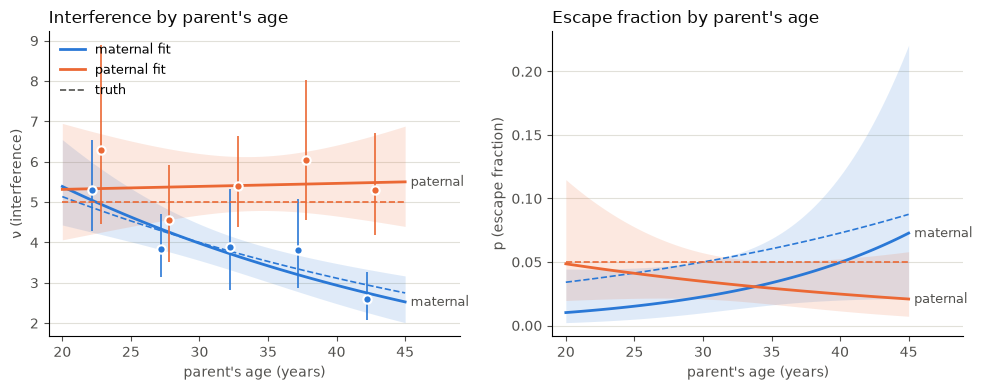

In [7]:
ages = np.linspace(20, 45, 101)
za = (ages - 30) / 10
q = norm.ppf(0.975)


def curve(theta, k, which):
    # Linear predictor and its gradient wrt theta for sex k: which = 0 for log nu, 1 for logit p.
    grad = np.zeros((za.size, 8))
    grad[:, 4 * which + k] = 1.0
    grad[:, 4 * which + 2 + k] = za
    return grad @ theta, grad


bins = np.arange(20, 50, 5)
bin_of = np.digitize(parent_age[parent], bins) - 1
_, p_fit = parameters(fit.x, s, z)


def bin_estimate(k, b):
    sel = (s == k) & (bin_of == b)
    sub = Meioses([data[i] for i in np.flatnonzero(sel)], L[sel])
    res = minimize(lambda t: -loglik_fast(sub, None, nu=np.exp(t[0]), p=p_fit[sel]),
                   x0=[np.log(4.0)], method="BFGS")
    return res.x[0], np.sqrt(res.hess_inv[0, 0])


ink, ink2, grid = "#0b0b0b", "#52514e", "#e1e0d9"
colours = ["#2a78d6", "#eb6834"]                  # maternal, paternal

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for which, (ax, transform, label) in enumerate(
        zip(axes, (np.exp, expit), ("ν (interference)", "p (escape fraction)"))):
    for k, name in enumerate(sexes):
        eta, grad = curve(fit.x, k, which)
        width = q * np.sqrt(np.einsum("ij,jk,ik->i", grad, cov, grad))
        ax.fill_between(ages, transform(eta - width), transform(eta + width), color=colours[k], alpha=0.15, lw=0)
        ax.plot(ages, transform(eta), color=colours[k], lw=2, label=f"{name} fit")
        ax.plot(ages, transform(curve(theta_true, k, which)[0]), color=colours[k], lw=1.2, ls="--")
        ax.text(ages[-1] + 0.4, transform(eta[-1]), name, color=ink2, fontsize=9, va="center")
        if which == 0:
            mids = bins[:-1] + 2.5
            est = np.array([bin_estimate(k, b) for b in tqdm(range(len(mids)), desc=f"{name} age bins")])
            ax.errorbar(mids + (k - 0.5) * 0.6, np.exp(est[:, 0]), color=colours[k], fmt="o", ms=6,
                        mec="white", mew=1.5, elinewidth=1.2, capsize=0,
                        yerr=[np.exp(est[:, 0]) - np.exp(est[:, 0] - q * est[:, 1]),
                              np.exp(est[:, 0] + q * est[:, 1]) - np.exp(est[:, 0])])
    ax.set_xlabel("parent's age (years)", color=ink2)
    ax.set_ylabel(label, color=ink2)
    ax.set_xlim(19, 49)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=ink2)
    ax.grid(axis="y", color=grid, lw=0.8)
    ax.set_axisbelow(True)
axes[0].plot([], [], color=ink2, lw=1.2, ls="--", label="truth")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
axes[0].set_title("Interference by parent's age", color=ink, loc="left")
axes[1].set_title("Escape fraction by parent's age", color=ink, loc="left")
fig.tight_layout()
plt.show()

## Notes

- **Other covariates.** Any model that maps covariates to one $(\nu_i, p_i)$ per meiosis works the
  same way: build the arrays, then call `loglik_fast` once. Covariates can also differ between
  meioses of one parent; with real data the parent's age at each birth is the natural choice.
- **Speed.** Each evaluation here (about 4,000 meioses) takes roughly 10 ms. With more than 16
  distinct $\nu$ values in one call, `ChebyshevKernel` falls back to the exact series, so it is not
  used here.
- **Families.** The model treats meioses of one parent as independent given the parent's
  covariates. Variation between parents beyond what the covariates explain would need a random
  effect per parent, as in a hierarchical model.
- **Bayesian version.** [The Metropolis–Hastings example](age_mcmc.ipynb) fits a model of this
  kind by sampling from the posterior.